# Image Classification using CNN

*   Creating deep networks using Keras
*   Training a neural network
*   Prediction and performance analysis using neural networks
*   Using pre-trained networks
*   Feature visualizations
---

# **Colaboratory environment**
By default, Colab notebooks run on CPU.
You can switch your notebook to run with GPU.

In order to obtain access to the GPU, you need to choose the tab Runtime and then select “Change runtime type” as shown in the following figure:

![Changing runtime](https://miro.medium.com/max/747/1*euE7nGZ0uJQcgvkpgvkoQg.png)

When a pop-up window appears select GPU. Ensure “Hardware accelerator” is set to GPU.

In [ ]:
import os
import warnings

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import tensorflow as tf
from matplotlib import pyplot as plt
from tensorflow import keras

tf.get_logger().setLevel("ERROR")

# **Working with a new dataset: CIFAR-10**

The CIFAR-10 dataset consists of 60000 32x32 colour images in 10 classes, with 6000 images per class. There are 50000 training images and 10000 test images. More information about CIFAR-10 can be found [here](https://www.cs.toronto.edu/~kriz/cifar.html).

In Keras, the CIFAR-10 dataset is also preloaded in the form of four Numpy arrays. x_train and y_train contain the training set, while x_test and y_test contain the test data. The images are encoded as Numpy arrays and their corresponding labels ranging from 0 to 9.

Step:

*   Visualize the images in CIFAR-10 dataset. Create a 10 x 10 plot showing 10 random samples from each class.
*   Convert the labels to one-hot encoded form.
*   Normalize the images.




In [ ]:
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print(x_train.shape)
print(x_train.ndim)
print(x_train.dtype)

print(x_test.shape)
print(np.unique(y_train, return_counts=True))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
(50000, 32, 32, 3)
4
uint8
(10000, 32, 32, 3)
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]))


In [ ]:
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
rng = np.random.default_rng(42)
fig, axes = plt.subplots(nrows=10, ncols=10, figsize=(15, 15))
for class_index, class_name in enumerate(class_names):
    class_indices = np.flatnonzero(y_train.reshape(-1) == class_index)
    selected_indices = rng.choice(class_indices, size=10, replace=False)
    for sample_index, image_index in enumerate(selected_indices):
        axis = axes[class_index, sample_index]
        axis.imshow(x_train[image_index])
        axis.axis("off")
        if class_index == 0:
            axis.set_title(f"{sample_index + 1}", fontsize=8)
    axes[class_index, 0].set_ylabel(class_name, rotation=0, labelpad=48, va="center", fontsize=9)
fig.suptitle("CIFAR-10 ? 10 random samples per class", y=1.01)
fig.tight_layout()
plt.show()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = keras.utils.to_categorical(y_train, num_classes=10)
y_test = keras.utils.to_categorical(y_test, num_classes=10)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

## Define the following model

**For the convolutional front-end, start with a single convolutional layer with a small filter size (3,3) and a modest number of filters (32) followed by a max pooling layer. Use the input as (32,32,3). The filter maps can then be flattened to provide features to the classifier. Use a dense layer with 100 units before the classification layer (which is also a dense layer with softmax activation).**

In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input

model = Sequential()
model.add(Input(shape=(32, 32, 3)))
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dense(100, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(10, activation='softmax'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       720,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 722,006 (2.75 MB)

 Trainable params: 722,006 (2.75 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [ ]:
# solution
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
history_shallow = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)


Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.2938 - loss: 1.9500 - val_accuracy: 0.4228 - val_loss: 1.6278
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.4736 - loss: 1.4963 - val_accuracy: 0.4680 - val_loss: 1.5417
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.5277 - loss: 1.3368 - val_accuracy: 0.5500 - val_loss: 1.3100
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5671 - loss: 1.2271 - val_accuracy: 0.5196 - val_loss: 1.3350
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6005 - loss: 1.1470 - val_accuracy: 0.5502 - val_loss: 1.2833
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6149 - loss: 1.0973 - val_accuracy: 0.5572 - val_loss: 1.2872
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6400 - loss: 1.0426 - val_accuracy: 0.5898 - val_loss: 1.1541
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6552 - loss: 0.9898 -

In [ ]:
fig, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(12, 4))
for key, label in (("loss", "Training"), ("val_loss", "Validation")):
    loss_axis.plot(history_shallow.history[key], label=label)
for key, label in (("accuracy", "Training"), ("val_accuracy", "Validation")):
    accuracy_axis.plot(history_shallow.history[key], label=label)
loss_axis.set(title="Baseline CNN ? Loss", xlabel="Epoch", ylabel="Loss")
accuracy_axis.set(title="Baseline CNN ? Accuracy", xlabel="Epoch", ylabel="Accuracy")
loss_axis.legend()
accuracy_axis.legend()
fig.tight_layout()
plt.show()

## Defining Deeper Architectures: VGG Models

*   Define a deeper model architecture for CIFAR-10 dataset and train the new model for 512 epochs with a batch size of 32. We will use VGG model as the architecture.

**Stack two convolutional layers with 32 filters, each of 3 x 3. Use a max pooling layer and next flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**


In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
# solution
deeper_model = Sequential()
deeper_model.add(Input(shape=(32, 32, 3)))
deeper_model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
deeper_model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', padding='same'))
deeper_model.add(MaxPooling2D((2, 2)))
deeper_model.add(Flatten())
deeper_model.add(Dense(128, activation='relu', kernel_initializer='he_uniform'))
deeper_model.add(Dense(10, activation='softmax'))

deeper_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,060,138 (4.04 MB)

 Trainable params: 1,060,138 (4.04 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [ ]:
# solution
deeper_model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
history_deeper = deeper_model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.3070 - loss: 1.9166 - val_accuracy: 0.4440 - val_loss: 1.5727
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4889 - loss: 1.4349 - val_accuracy: 0.4512 - val_loss: 1.5615
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.5568 - loss: 1.2457 - val_accuracy: 0.5218 - val_loss: 1.3759
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6080 - loss: 1.1146 - val_accuracy: 0.5488 - val_loss: 1.2755
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6472 - loss: 1.0069 - val_accuracy: 0.5694 - val_loss: 1.2361
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.6790 - loss: 0.9173 - val_accuracy: 0.5992 - val_loss: 1.1803
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7063 - loss: 0.8416 - val_accuracy: 0.6550 - val_loss: 1.0071
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.7369 - loss: 0.7578 - 

*   Compare the performance of both the models by plotting the loss and accuracy curves of both the training steps. Does the deeper model perform better?


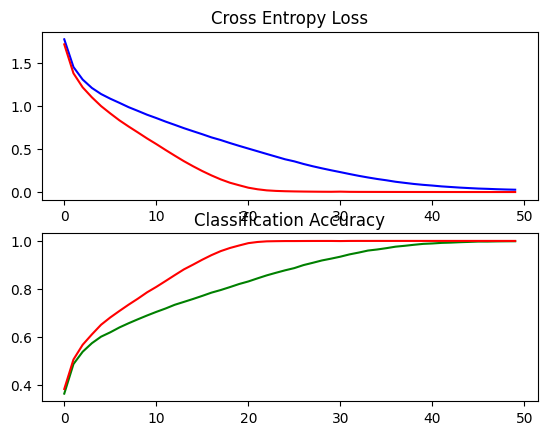

In [ ]:
# solution

plt.subplot(211)
plt.title('Cross Entropy Loss')
plt.plot(history_shallow.history['loss'], color='blue', label='tutorial')
plt.plot(history_deeper.history['loss'], color='red', label='deep')

plt.subplot(212)
plt.title('Classification Accuracy')
plt.plot(history_shallow.history['accuracy'], color='green', label='tutorial')
plt.plot(history_deeper.history['accuracy'], color='red', label='deep')
plt.show()

*   Use predict function to predict the output for the test split
*   Plot the confusion matrix for the new model and comment on the class confusions.


In [ ]:
# Evaluate the baseline CNN on the CIFAR-10 test split.
predictions = model.predict(x_test, verbose=0).argmax(axis=1)
y_test_labels = y_test.argmax(axis=1)
print(predictions.shape, y_test_labels.shape)

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_labels, predictions, labels=np.arange(10))
fig, axis = plt.subplots(figsize=(10, 8))
image = axis.imshow(cm, cmap="Blues")
threshold = cm.max() / 2.0
for row, column in np.ndindex(cm.shape):
    axis.text(column, row, cm[row, column], ha="center", va="center",
              color="white" if cm[row, column] > threshold else "black", fontsize=8)
axis.set(title="Baseline CNN ? CIFAR-10 test confusion matrix", xlabel="Predicted label", ylabel="True label")
axis.set_xticks(np.arange(10), labels=class_names, rotation=45, ha="right")
axis.set_yticks(np.arange(10), labels=class_names)
fig.colorbar(image, ax=axis, label="Number of images")
fig.tight_layout()
plt.show()

*    Print the test accuracy for the trained model.

In [ ]:
from sklearn.metrics import classification_report

test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f"Baseline CNN test accuracy: {test_accuracy:.4f}")
print(f"Baseline CNN test loss: {test_loss:.4f}")
print(classification_report(
    y_test_labels,
    predictions,
    labels=np.arange(10),
    target_names=class_names,
    digits=3,
    zero_division=0,
))

## Define the complete VGG architecture.

**Stack two convolutional layers with 64 filters, each of 3 x 3 followed by max pooling layer. Stack two more convolutional layers with 128 filters, each of 3 x 3, followed by max pooling, follwed by two more convolutional layers with 256 filters, each of 3 x 3, followed by max pooling. Flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**

*   Change the size of input to 64 x 64.

In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
vgg_net = keras.Sequential([
    keras.Input(shape=(64, 64, 3)),
    keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2d"),
    keras.layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="block1_conv2"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="block2_conv1"),
    keras.layers.Conv2D(128, (3, 3), activation="relu", padding="same", name="block2_conv2"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(256, (3, 3), activation="relu", padding="same", name="block3_conv1"),
    keras.layers.Conv2D(256, (3, 3), activation="relu", padding="same", name="block3_conv2"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
], name="vgg_net")
vgg_net.summary()

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 100 epochs with a batch size of 32.
*   Predict the output for the test split and plot the confusion matrix for the new model and comment on the class confusions.

In [ ]:
from sklearn.model_selection import train_test_split

train_indices, val_indices = train_test_split(
    np.arange(len(y_train)),
    test_size=0.1,
    stratify=y_train.argmax(axis=1),
    random_state=42,
)

def _resize_vgg_batch(images, labels):
    return tf.image.resize(images, (64, 64), method="bilinear"), labels

def _vgg_dataset(images, labels, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, labels))
    if shuffle:
        dataset = dataset.shuffle(len(images), seed=42, reshuffle_each_iteration=True)
    return (
        dataset.batch(32)
        .map(_resize_vgg_batch, num_parallel_calls=tf.data.AUTOTUNE)
        .prefetch(tf.data.AUTOTUNE)
    )

vgg_train = _vgg_dataset(x_train[train_indices], y_train[train_indices], shuffle=True)
vgg_validation = _vgg_dataset(x_train[val_indices], y_train[val_indices])
vgg_test = _vgg_dataset(x_test, y_test)
vgg_net.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
history_vgg = vgg_net.fit(vgg_train, epochs=100, validation_data=vgg_validation)
vgg_test_loss, vgg_test_accuracy = vgg_net.evaluate(vgg_test, verbose=0)
print(f"VGG test accuracy: {vgg_test_accuracy:.4f}; loss: {vgg_test_loss:.4f}")

In [ ]:
def plot_vgg_feature_maps(image, class_name):
    """Display all 64 first-convolution feature maps for a CIFAR-10 image."""
    image = tf.convert_to_tensor(image[None, ...], dtype=tf.float32)
    image = tf.image.resize(image, (64, 64), method="bilinear")
    feature_model = keras.Model(vgg_net.input, vgg_net.get_layer("conv2d").output)
    feature_maps = feature_model.predict(image, verbose=0)[0]
    if feature_maps.shape[-1] != 64:
        raise ValueError(f"Expected 64 feature maps, found {feature_maps.shape[-1]}.")
    figure, axes = plt.subplots(8, 8, figsize=(12, 12))
    for index, axis in enumerate(axes.flat):
        axis.imshow(feature_maps[:, :, index], cmap="viridis")
        axis.axis("off")
    figure.suptitle(f"conv2d feature maps ? input class: {class_name}")
    figure.subplots_adjust(left=0, right=1, bottom=0, top=0.96, wspace=0.02, hspace=0.02)
    plt.show()

plot_vgg_feature_maps(x_train[0], class_names[int(y_train[0].argmax())])

# Understanding deep networks

*   What is the use of activation functions in network? Why is it needed?
*   We have used softmax activation function in the exercise. There are other activation functions available too. What is the difference between sigmoid activation and softmax activation?
*   What is the difference between categorical crossentropy and binary crossentropy loss?

# Transfer Learning

It is not always necessary to train models from scratch. We can use the knowledge of networks trained on other tasks to learn the task at hand. In this exercise, we will explore the use of pre-trained weights and train on the CIFAR-10 dataset.

*   Create a base imagenet pretrained InceptionV3 model.
    *    Hint: Use tf.keras.applications to create the model
    *    Pay attention to the include_top parameter.
*    Add a global average pooling layer, followed by a fully-connected layer with 1024 neurons and then the classification layer.
*   Train the model by freezing the base model. Train only the newly added layers.
    *    Hint: Every layer has an attribute called 'trainable'
*   Compile the model and train the model for a few epochs only.

In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
# solution
from keras.applications import InceptionV3
from tensorflow.keras.optimizers import Adam
from keras.layers import Dense, GlobalAveragePooling2D
from keras.models import Model

inception_model = InceptionV3(
    include_top=False,
    weights="imagenet",
    input_tensor=None,
    input_shape=None,
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
    name="inception_v3",
)

# freeze the base model
for layer in inception_model.layers:
    layer.trainable = False

x = inception_model.output
x = GlobalAveragePooling2D(name="global_avg_pool")(x)
x = Dense(1024, activation='relu', name="custom_dense")(x)
predictions = Dense(10, activation='softmax', name="predictions")(x)

model = Model(inputs=inception_model.input, outputs=predictions)

learning_rate = 0.001
model.compile(optimizer=Adam(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
# model.summary()

In [ ]:
from tensorflow.keras.applications import InceptionV3

inception_model = InceptionV3(
    include_top=False,
    weights="imagenet",
    input_shape=(75, 75, 3),
    pooling="avg",
    name="inception_v3",
)
inception_model.trainable = False
inputs = keras.Input(shape=(75, 75, 3))
x = keras.layers.Rescaling(2.0, offset=-1.0, name="inception_preprocess")(inputs)
x = inception_model(x, training=False)
x = keras.layers.Dense(1024, activation="relu", name="custom_dense")(x)
predictions = keras.layers.Dense(10, activation="softmax", name="predictions")(x)
model = keras.Model(inputs=inputs, outputs=predictions)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

In [ ]:
# Resize CIFAR-10 images to the required InceptionV3 minimum size; inputs remain in [0, 1].
x_train_small = tf.image.resize(x_train[:1000], (75, 75), method="bilinear").numpy()

*    Freeze the bottom layers and unfreeze the base layers.
*    Compile and train the classifier with a very low learning rate (0.0001)

In [ ]:
for layer in inception_model.layers:
  layer.trainable = True
for layer in model.layers:
  if layer.name in ['custom_dense', 'predictions']:
    layer.trainable = False
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_188 (Conv2D) │ (None, None,      │        864 │ input_layer_2[0]… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │         96 │ conv2d_188[0][0]  │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_188      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_189 (Conv2D) │ (None, None,      │      9,216 │ activation_188[0… │
│                     │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │         96 │ conv2d_189[0][0]  │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_189      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_190 (Conv2D) │ (None, None,      │     18,432 │ activation_189[0… │
│                     │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        192 │ conv2d_190[0][0]  │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_190      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, None,      │          0 │ activation_190[0… │
│ (MaxPooling2D)      │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_191 (Conv2D) │ (None, None,      │      5,120 │ max_pooling2d_8[… │
│                     │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        240 │ conv2d_191[0][0]  │
│ (BatchNormalizatio… │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_191      │ (None, None,      │          0 │ batch_normalizat… │
│ (Activation)        │ None, 80)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_192 (Conv2D) │ (None, None,      │    138,240 │ activation_191[0… │
│                     │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        576 │ conv2d_192[0][0]  │
│ (BatchNormalizatio… │ None, 192)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_192      │ (None, None,      │          0 │ batch_normalizat

 Total params: 23,911,210 (91.21 MB)

 Trainable params: 21,768,352 (83.04 MB)

 Non-trainable params: 2,142,858 (8.17 MB)

*    When do we train models from scratch? What are the potential issues in training models from scratch?

*    Why do we use pre-trained weights?
*    What is the difference between using random initialization and using weights from a pre-trained model?

# Extracting features from Deep Networks

It is quite possible to extract features (similar to SIFT or ORB) from different layers of deep network.

*   Load ResNet50 model with imagenet weights and check the summary of the model
*   Create a model to extract features from the 'avg_pool' layer.
*   Extract features from the layer for all the train images.
*   Use the extracted features to train a SVM classifier.
    *    Use GridSearchCV and SVC to perform the classification

In [ ]:
# solution
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import Model

model = ResNet50()
model.summary()

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,636,712 (97.80 MB)

 Trainable params: 25,583,592 (97.59 MB)

 Non-trainable params: 53,120 (207.50 KB)

*    Evaluate the trained SVM model using the test set
*    Calculate the accuracy score and confusion matrix

In [ ]:
# solution
from skimage import transform

extract = Model(model.inputs, model.get_layer('avg_pool').output)

dl_feature_descriptors = []

N = 50
# get N examples per class
x_train_stratified = np.empty((10*N,)+x_train[0].shape)
y_train_stratified = np.empty((10*N,)+y_train[0].shape)
for cl in range(10):
  x_train_stratified[cl*N:(cl+1)*N] = x_train[np.where(np.argmax(y_train, axis=1) == cl)[0][:N]]
  y_train_stratified[cl*N:(cl+1)*N] = y_train[np.where(np.argmax(y_train, axis=1) == cl)[0][:N]]
print(np.unique(np.argmax(y_train_stratified, axis=1), return_counts=True))

# resize to 224x224x3
x_train_stratified = np.array([
  transform.resize(img, (224, 224, 3), preserve_range=True, anti_aliasing=True) 
  for img in x_train_stratified
  ])
batch_size = 32
for i in range(0, len(x_train_stratified), batch_size):
  example = x_train_stratified[i:i+batch_size]
  desc = extract.predict(example)
  dl_feature_descriptors.append(desc)

dl_feature_descriptors = np.concatenate(dl_feature_descriptors, axis=0)
print(dl_feature_descriptors.shape)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([50, 50, 50, 50, 50, 50, 50, 50, 50, 50]))


1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
(500, 2048)


# Feature Visualizations

In order to visualize the features of a higher dimension data, t-SNE is used. t-SNE converts the affinities of the data points to probabilities. It recreates the probability distribution in a low-dimensional space. It is very helpful in visualizing features of different layers in a neural network.

You can find more information about t-SNE [here](https://scikit-learn.org/stable/modules/manifold.html#t-distributed-stochastic-neighbor-embedding-t-sne)

*    Use TSNE to visualize the features extracted in the previous exercise.
    *    Hint: TSNE function is available in the *sklearn.manifold* package.

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] Computing 121 nearest neighbors...
[t-SNE] Indexed 500 samples in 0.002s...
[t-SNE] Computed neighbors for 500 samples in 0.086s...
[t-SNE] Computed conditional probabilities for sample 500 / 500
[t-SNE] Mean sigma: 0.148360
[t-SNE] KL divergence after 250 iterations with early exaggeration: 55.187542
[t-SNE] KL divergence after 300 iterations: 0.865431


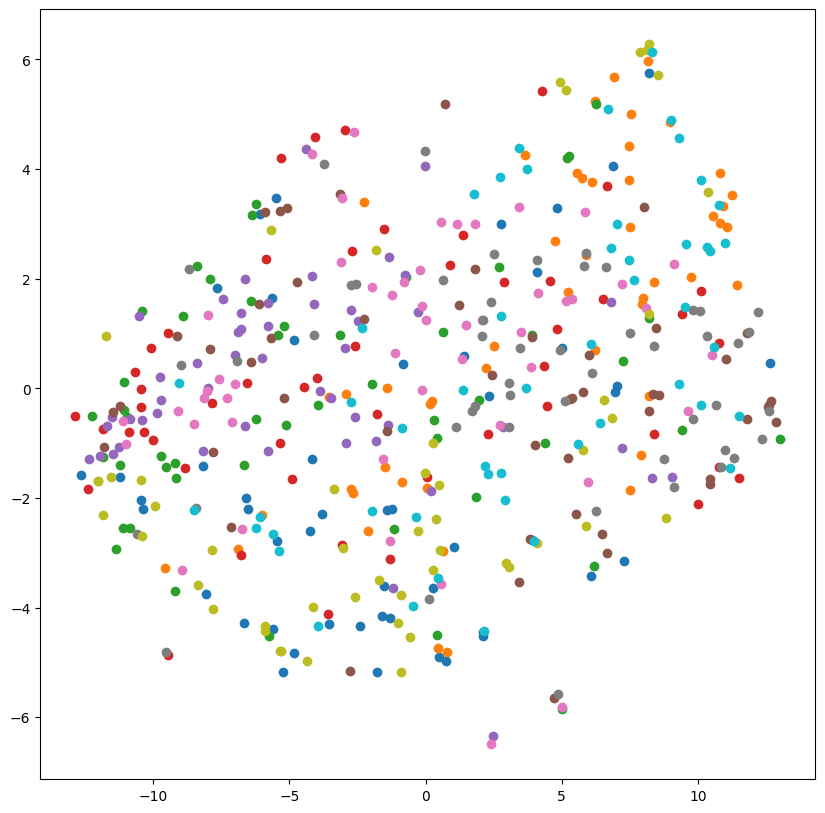

In [ ]:
# solution
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, verbose=1, perplexity=40, n_iter=300)
tsne_results = tsne.fit_transform(dl_feature_descriptors)

plt.figure(figsize=(10, 10))
for cl in range(10):
  plt.scatter(tsne_results[np.where(np.argmax(y_train_stratified, axis=1) == cl)][:, 0],
              tsne_results[np.where(np.argmax(y_train_stratified, axis=1) == cl)][:, 1],
              label=cl)
plt.show()


*    Why is feature visualization helpful?